In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy
import time

In [2]:
# Signal and system parameters

c = 3e8
f_c = 3.6192e9
bandwidth = 20e6
N_cp = 72
scs = 30e3

if bandwidth == 20e6:
    f_s = 30.72e6
    N_ifft = 1024
    nPRB = 51
    occ_bandwidth = 12*nPRB*scs
    
elif bandwidth == 40e6:
    f_s = 61.44e6
    N_ifft = 2048
    nPRB = 106
    occ_bandwidth = 12*nPRB*scs

osf = 8
N_ant = 4
d_ant = 1/2*np.arange(0, N_ant, 1) # inter-element distance (in terms of wavelength)
P_t = 0.1 # Watt
K = 1.380649e-23
T = 298
noise_var = K*bandwidth*T

In [ ]:
# # Channel parameters

# K = 10
# Dist = 13 # Distance of UE from gNB in meters
# tau = 1/c*np.transpose(np.array([np.zeros(K), 20*np.random.rand(K)+9, 30*np.random.rand(K)+9])) # Transmit delay in s (converted from meters)
# theta = np.pi/180*np.transpose(np.array([np.zeros(K), -60*np.random.rand(K)-10, 60*np.random.rand(K)+10])) # AoA in radians (converted from degrees)
# Doppler = np.zeros([K, 3]) # Doppler in Hz (converted from m/s)
# free_space = P_t*(c/f_c*1/(4*np.pi*Dist))**2
# free_space = free_space/noise_var
# pathgain = free_space*np.array([1, 0.2, 0.07])

In [20]:
# Channel parameters

chan_params = np.load('/home/bkumar2/Documents/Research/sionna_env/Sionna_scripts/positioning_chan3.npy')

SDO = 1e-9*np.array([0, 10, 17, 42])

K = 50
tau = chan_params[:, 2, :] # Transmit delay in s 
theta = chan_params[:, 0, :] # AoA in radians
Doppler = chan_params[:, 1, :] # Doppler in Hz (converted from m/s)
pathgain = chan_params[:, 3, :] # Pathgain in absolute value

# Repeat the same values K times for averaging (Monte carlo simulation)
# tau = np.tile(np.reshape(tau, [1, N_ant, len(tau)]), [K, 1, 1])
# Doppler = np.tile(np.reshape(Doppler, [1, N_ant, len(Doppler)]), [K, 1, 1])
pathgain = P_t*pathgain/noise_var

In [21]:
# Generate the received signal

# No. of paths
L = np.shape(tau)[1]

# Generated signal for K scenarios, N_ant antennas and N_ifft samples
gen_signal = np.zeros([K, N_ant, N_ifft], dtype=np.complex128)

# Transmitted OFDM symbols
Xn = np.random.randint(0, 4, [12*nPRB])
Xn = np.exp(1j*(np.pi*Xn/2 + np.pi/4))
Xn = np.concatenate([Xn[0:6*nPRB], np.zeros(N_ifft - 12*nPRB), Xn[6*nPRB:12*nPRB]])
Xn = np.reshape(Xn, [N_ifft, 1])

t = np.arange(N_cp, N_cp+N_ifft, 1)/f_s # Sampling timestamps, starts from N_cp because we discard the first N_cp samples
n = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(-N_ifft//2, 0, 1)])
n = np.reshape(n, [N_ifft, 1])
n = np.tile(n, [1, N_ifft])

# This loop just generates the OFDM samples in time domain
for k in range(0, K):
    for n_ant in range(0, N_ant):
        for l in range(0, L):
            phase = np.exp(1j*2*np.pi*np.random.rand())
            gen_signal[k, n_ant, :] = gen_signal[k, n_ant, :] + 1/(np.sqrt(N_ifft))*np.sqrt(pathgain[n_ant, l]) * phase * \
                        np.exp(1j*2*np.pi*Doppler[n_ant, l]*t) * \
                        np.sum(np.tile(Xn, [1, N_ifft])*np.exp(1j*2*np.pi*scs*n*np.tile(np.reshape(t-N_cp/f_s-tau[n_ant, l]-SDO[n_ant], [1, N_ifft]), [N_ifft, 1])), axis=0)


# Add the AWGN noise to the generated samples
rcvd_signal = gen_signal + np.random.normal(size=[K, N_ant, N_ifft])

# Convert the received samples back to frequency domain to estimate the OFDM symbols or channel
rcvd_sig_freq = 1/np.sqrt(N_ifft)*np.fft.fft(rcvd_signal, axis=2)

# Estimate the channel using Xn as pilot symbols
H = np.zeros([K, N_ant, N_ifft], dtype=np.complex128) 

for i in range(0, N_ifft):
    if Xn[i] == 0:
        H[:, :, i] = np.zeros([K, N_ant])
    else:
        H[:, :, i] = rcvd_sig_freq[:, :, i]*np.conjugate(np.tile(Xn[i, 0], [K, N_ant]))

In [74]:
# Plotting the estimated channel in time domain (CIR)

%matplotlib qt
oversampled_H = np.concatenate([H[0, 0, 0:N_ifft//2], np.zeros((osf-1)*N_ifft), H[0, 0, N_ifft//2:N_ifft]])
cir = np.fft.ifft(oversampled_H)
plt_osf = 1
cir = np.concatenate([cir[-(plt_osf*N_ifft)//2:], cir[0:(plt_osf*N_ifft)//2]])

plt.semilogy(np.arange(-(plt_osf*N_ifft)//2, (plt_osf*N_ifft)//2, 1)/(8*f_s), np.abs(cir))
plt.xlabel("Time (us)", fontsize=30)
plt.ylabel("CIR", fontsize=30)
plt.xticks(fontsize=24)
plt.yticks(fontsize=24)
plt.show()

[[16.27604167 24.4140625  44.75911458 61.03515625]
 [16.27604167 32.55208333 40.69010417 56.96614583]
 [16.27604167 24.4140625  36.62109375 56.96614583]
 [16.27604167 40.69010417 40.69010417 61.03515625]
 [16.27604167 28.48307292 32.55208333 61.03515625]
 [20.34505208 28.48307292 28.48307292 61.03515625]
 [16.27604167 32.55208333 36.62109375 61.03515625]
 [16.27604167 24.4140625  32.55208333 61.03515625]
 [24.4140625  32.55208333 24.4140625  65.10416667]
 [12.20703125 32.55208333 36.62109375 61.03515625]
 [20.34505208 20.34505208 36.62109375 56.96614583]
 [24.4140625  28.48307292 24.4140625  61.03515625]
 [20.34505208 24.4140625  24.4140625  61.03515625]
 [12.20703125 32.55208333 36.62109375 56.96614583]
 [16.27604167 20.34505208 28.48307292 61.03515625]
 [16.27604167 28.48307292 40.69010417 56.96614583]
 [24.4140625  32.55208333 24.4140625  56.96614583]
 [16.27604167 28.48307292 24.4140625  61.03515625]
 [20.34505208 32.55208333 36.62109375 56.96614583]
 [16.27604167 28.48307292 40.69

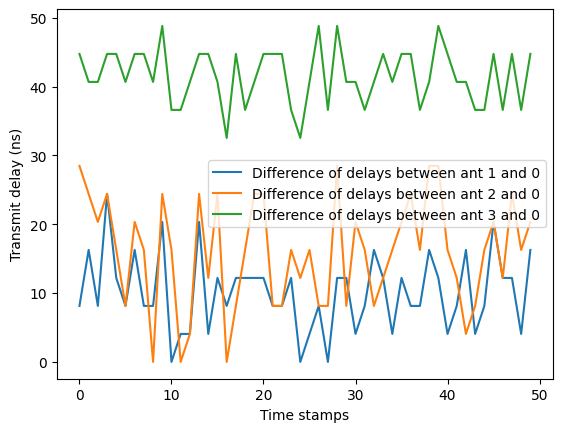

In [22]:
H_time = np.zeros([K, N_ant, osf*N_ifft], dtype=np.complex64)
est_tof = np.zeros([K, N_ant])

for k in range(0, K):
    for n_ant in range(0, N_ant):
        H_time[k, n_ant, :] = np.sqrt(N_ifft)*np.fft.ifft(np.concatenate([H[k, n_ant, 0:N_ifft//2], np.zeros([(osf-1)*N_ifft]), H[k, n_ant, N_ifft//2:N_ifft]]))

        max_idx = np.argmax(np.abs(H_time[k, n_ant, :]))
        if max_idx > (osf*N_ifft) // 2:
            max_idx = -(osf*N_ifft - max_idx)

        est_tof[k, n_ant] = 1e9*max_idx/(osf*f_s)

print(est_tof)

plt.plot(np.arange(0, K, 1), est_tof[:, 1] - est_tof[:, 0])
plt.plot(np.arange(0, K, 1), est_tof[:, 2] - est_tof[:, 0])
plt.plot(np.arange(0, K, 1), est_tof[:, 3] - est_tof[:, 0])
plt.xlabel("Time stamps")
plt.ylabel("Transmit delay (ns)")

plt.legend(["Difference of delays between ant 1 and 0", "Difference of delays between ant 2 and 0", "Difference of delays between ant 3 and 0"])

In [ ]:
# Implementation of mD-Track algorithm
%matplotlib qt

L = 3 # No. of paths we are estimating
RMSE = np.zeros([2, L]) # RMSE for ToA and AoA for all the estimated paths

# First step is regenerating the received samples in time domain from the estimated channel and known pilot symbols (Xn) for all 4 different antennas
complex_rxsym0 = H[:, 0, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym0 = np.concatenate([complex_rxsym0[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym0[:, N_ifft//2:N_ifft]], axis=1)
complex_time0 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym0, axis=1)
complex_rxsym1 = H[:, 1, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym1 = np.concatenate([complex_rxsym1[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym1[:, N_ifft//2:N_ifft]], axis=1)
complex_time1 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym1, axis=1)
complex_rxsym2 = H[:, 2, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym2 = np.concatenate([complex_rxsym2[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym2[:, N_ifft//2:N_ifft]], axis=1)
complex_time2 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym2, axis=1)
complex_rxsym3 = H[:, 3, :]*np.tile(np.reshape(Xn[:, 0], [1, N_ifft]), [K, 1])
complex_rxsym3 = np.concatenate([complex_rxsym3[:, 0:N_ifft//2], np.zeros([K, (osf-1)*N_ifft]), complex_rxsym3[:, N_ifft//2:N_ifft]], axis=1)
complex_time3 = np.sqrt(N_ifft)*np.fft.ifft(complex_rxsym3, axis=1)

# This is the IFFT samples of the OFDM symbols (This is later used in estimating the Doppler and ToA using Ambiguity function)
Xn_os = np.concatenate([Xn[0:N_ifft//2, 0], np.zeros((osf-1)*N_ifft), Xn[N_ifft//2:N_ifft, 0]])
time_gensym = np.sqrt(N_ifft)*np.fft.ifft(Xn_os)

# n_Dopp = np.concatenate([np.arange(0, N_ifft//2, 1), np.arange(0, N_ifft//2, 1)])

for iter0 in range(0, K):
    est_mean_time0 = complex_time0[iter0, :]
    est_mean_time1 = complex_time1[iter0, :]
    est_mean_time2 = complex_time2[iter0, :]
    est_mean_time3 = complex_time3[iter0, :]

    mean_chan_subcarrier = np.concatenate([[est_mean_time0], [est_mean_time1], [est_mean_time2], [est_mean_time3]], axis=0)

    resolve = 5 # In mDTrack, the algorithm iteratively estimates the channel parameters. This variable sets the number of such iterations.
    parameters = np.zeros([4, L], dtype=np.complex128) # Save the estimated channel parameters in this array

    # Search space for the parameters
    f_search = np.arange(-2000, 2000, 1000)
    t_search = np.arange(-50, 50, 1)
    theta_search = np.arange(-5*np.pi/12, 5*np.pi/12, 0.1)

    print("-------------------- Symbol no. {} --------------------".format(iter0))
    
    for iter in range(0, resolve):

        beam_strength = np.zeros([len(theta_search), L])
        caf = np.zeros([len(f_search), len(t_search), L])
        
        for l in range(0, L):

            # After the first iteration, we refine the estimated parameters in the remaining iterations (Check mDTrack paper)
            if iter > 0:
                generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant,1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(np.real(parameters[0, l]))), [N_ant, 1]), [1, osf*N_ifft])
                generated_sig = np.roll(generated_sig, int(np.real(parameters[2, l])), axis=1)
                generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*np.real(parameters[1, l])*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])
                generated_sig = parameters[3, l]*generated_sig
                mean_chan_subcarrier = generated_sig + residual_sig

            if iter > 2:
                theta_search = np.arange(-np.pi/24, np.pi/24, 0.01) + np.real(parameters[0, l])
                f_search = np.arange(-200, 200, 100) + np.real(parameters[1, l])

            est_mean_rxsym = mean_chan_subcarrier*np.conjugate(np.tile(mean_chan_subcarrier[0:1, :], [N_ant,1]))

            mean_chan = np.average(est_mean_rxsym, axis=1)

            # START - Code for beam sweeping here and finding the strongest direction.

            for i in range(0, len(theta_search)):
                beam_strength[i, l] = np.abs(np.sum(mean_chan*np.exp(-1j*2*np.pi*d_ant*np.sin(theta_search[i]))))
                
            # if iter == 0:
            #     plt.figure(2*L*iter + 2*l)
            #     plt.polar(theta_search, beam_strength[:, l])

            max_idx = np.argmax(beam_strength[:, l])
            max_theta = theta_search[max_idx] 

            parameters[0, l] = max_theta
            # END - Code for beam sweeping here and finding the strongest direction.

            time2 = time.time()

            # START - Code for estimating the transmit delay and Doppler using CAF (Cross Ambiguity function)

            n = np.arange(0, osf*N_ifft, 1)

            combined_chan = np.sum(np.tile(np.reshape(np.exp(-1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])*mean_chan_subcarrier, axis=0)
            
            for f in range(0, len(f_search)):
                for t in range(0, len(t_search)):
                    temp_caf = np.roll(np.conj(time_gensym), t_search[t])*combined_chan
                    caf[f, t, l] = np.abs(np.sum(temp_caf*np.exp(-1j*2*np.pi*f_search[f]*n/(osf*f_s))))

            idx = np.argmax(caf[:, :, l])
            f_best, t_best = np.unravel_index(idx, caf[:, :, l].shape)

            parameters[1, l] = f_search[f_best]
            parameters[2, l] = t_search[t_best]

            # END - Code for estimating the transmit delay and Doppler using CAF

            # if iter == resolve-1:
            #     plt.figure(2*L*iter + 2*l+1)
            #     plt.imshow(caf[:, :, l], cmap='hot', interpolation='nearest')
            #     plt.xlabel("Delay sweep")
            #     plt.ylabel("Doppler sweep")

            # START - Code that is used to regenerate the signal using the estimated parameters

            generated_sig = np.tile(np.reshape(time_gensym, [1,osf*N_ifft]), [N_ant,1])*np.tile(np.reshape(np.exp(1j*2*np.pi*d_ant*np.sin(max_theta)), [N_ant, 1]), [1, osf*N_ifft])

            generated_sig = np.roll(generated_sig, t_search[t_best], axis=1)

            generated_sig = generated_sig*np.tile(np.reshape(np.exp(1j*2*np.pi*f_search[f_best]*n/(osf*f_s)), [1, osf*N_ifft]), [N_ant,1])

            alpha = np.average(mean_chan_subcarrier/generated_sig)

            parameters[3, l] = alpha

            generated_sig = alpha*generated_sig

            residual_sig = mean_chan_subcarrier - generated_sig

            mean_chan_subcarrier = residual_sig

            if iter == resolve-1:
                print("Path no. {} - estimated delay is {} ns and estimated AoA is {}°".format(l, t_search[t_best]/(osf*f_s)*1e9, 180/np.pi*max_theta))
                # print("Path no. {} - true delay is {} ns and true AoA is {}°".format(l, tau[iter0, l]*1e9, 180/np.pi*theta[iter0, l]))
                # print("Estimated Doppler is {} Hz".format(f_search[f_best]))
                # print("Estimated path gain is {}".format(alpha))

                # if iter0 != 2:
                RMSE[0, l] = RMSE[0, l] + (tau[iter0, l]*1e9 - tau[iter0, 0]*1e9 - np.real(parameters[2,l])/(osf*f_s)*1e9 + np.real(parameters[2,0])/(osf*f_s)*1e9)**2
                RMSE[1, l] = RMSE[1, l] + (180/np.pi*theta[iter0, l] - 180/np.pi*np.real(parameters[0,l]))**2

            if iter == resolve-1 and l == L-1:
                plt.figure(iter0)
                plt.scatter(180/np.pi*np.real(parameters[0, :]), np.real(parameters[2, :])/(osf*f_s)*1e9, c='b', marker='o', linewidth=10)
                plt.xlabel("AoA (degrees)", fontsize=30)
                plt.ylabel("Transmit delay (ns)", fontsize=30)
                plt.grid(True)
                plt.xticks(fontsize=30)
                plt.yticks(fontsize=30)

        # END - Code that is used to regenerate the signal using the estimated parameters

RMSE = np.sqrt(RMSE/(K))

time3 = time.time()
# print("The timestamps for the program are = {}, {}, {}, {}".format(time0, time1, time2, time3))
# print(parameters)
plt.show()

-------------------- Symbol no. 0 --------------------
Path no. 0 - estimated delay is 0.0 ns and estimated AoA is 4.538036196585895°
Path no. 1 - estimated delay is 73.2421875 ns and estimated AoA is -65.93577260450542°
Path no. 2 - estimated delay is 109.86328125 ns and estimated AoA is 20.00789666511814°
-------------------- Symbol no. 1 --------------------
Path no. 0 - estimated delay is 0.0 ns and estimated AoA is 4.538036196585895°
Path no. 1 - estimated delay is 65.10416666666667 ns and estimated AoA is -68.80056158015955°
Path no. 2 - estimated delay is 105.79427083333333 ns and estimated AoA is 20.58085446024896°
-------------------- Symbol no. 2 --------------------
Path no. 0 - estimated delay is 0.0 ns and estimated AoA is 4.538036196585895°
Path no. 1 - estimated delay is 65.10416666666667 ns and estimated AoA is -66.50873039963624°
Path no. 2 - estimated delay is 109.86328125 ns and estimated AoA is 17.71606548459484°
-------------------- Symbol no. 3 -------------------

In [31]:
print(180/np.pi*theta[0, :])
print(1e9*tau[0, :])
print(np.sqrt(pathgain))

[   4.39870079  -68.03600177  161.07497582    4.39870079    4.39870079
   -5.83764224 -129.45459639   24.86047223 -157.98045116    4.39870079
  -55.32369467 -159.1445203     4.39870079 -158.10837377  167.54987221]
[  0.          72.33168731 111.77944259   6.14501516   2.61860578
  28.20491929 100.44702492  84.4891872   20.30420276   6.21770369
  49.36206821  34.04428739   2.6697613   20.37884528  49.6003274 ]
[573.881017    93.17268712  69.19710647  44.28122016  38.85240193
  32.13662679  27.09416402  16.10868456  14.39062694   5.01647323
   4.93226169   4.06976957   3.96037836   1.62436447   0.72484667]


In [24]:
print(180/np.pi*theta[0, :])

[   4.39870079    6.2456864   -41.03103206  -68.03600177 -129.45459639
  161.07497582  106.9353294   -68.03600177   24.86047223    4.39870079
    4.39870079   -5.83764224   31.23672702   17.11796786 -159.1445203
    6.18435813 -158.10837377    4.39870079  167.54987221]


In [25]:
print(1e9*tau[0, :])

[  0.           3.00168779  24.41380431  72.33168731 100.44702492
 111.77944259 136.12223881  73.34269014  84.4891872    6.14501516
   2.61860578  28.20491929  43.524917    55.24873714  34.04428739
   8.2780609   20.37884528   2.6697613   49.6003274 ]


In [26]:
print(np.sqrt(pathgain))

[573.881017   536.68923688 367.69615301 215.98029624 173.84412157
 161.19233385 139.32455451 100.50663301  79.44585298  44.28122016
  38.85240193  32.13662679  29.89300492  14.65109473  11.12762688
   7.62127027   4.36864482   3.96037836   1.80273224]


[[0.         1.29187058 1.5083403 ]
 [0.04562616 1.35246076 2.66439081]]


Text(0.5, 0, 'Path index')

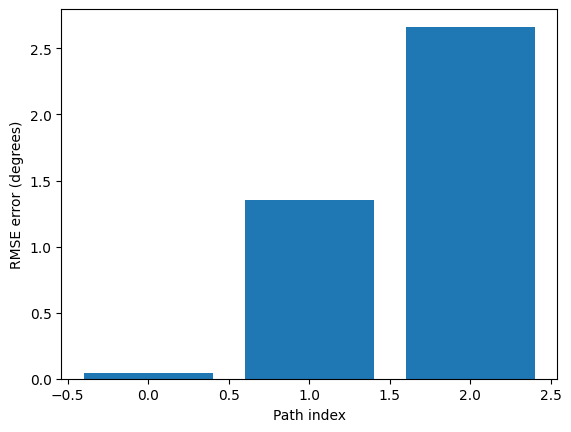

In [44]:
print(RMSE)
plt.bar(np.arange(0, 3, 1), RMSE[1, :])
plt.ylabel('RMSE error (degrees)')
plt.xlabel("Path index")